# 03 · Exploratory Data Analysis

**Requirements covered:** *EDA to be done and demonstrated* · *Visualize city-wise AQI, pollutant correlations and yearly/monthly trends* · *time-series EDA* · *festival / winter indicators* · *EDA notebook with pollutant and city comparison plots*.

Questions we answer
1. What does the dataset cover, and how good is it? (coverage, distributions, outliers, the Ahmedabad anomaly)
2. How polluted is each city and how do the AQI categories distribute?
3. How does AQI change over **years, months, weekdays**?
4. How do pollutants relate to each other and to the AQI? Which pollutant drives the AQI?
5. **Festival effects** (Diwali, Holi, Dussehra), the **stubble-burning season** and the **COVID-19 lockdown** as a natural experiment.
6. What does all this imply for modelling?

Data: the `aqi_features` table written by notebook 02 (28,157 cleaned city-days). Comparisons exclude the suspect city (Ahmedabad) unless stated.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings; warnings.filterwarnings("ignore")
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates, seaborn as sns
from scipy import stats

from src import db, config, cpcb
from src.config import (POLLUTANTS, MODEL_POLLUTANTS, LABELS, BUCKET_ORDER, BUCKET_COLORS, CORE_CITIES, COMPARE_CITIES,
                        NORTH_CITIES, FESTIVALS, LOCKDOWN_START, LOCKDOWN_END)
from src.viz import set_style, save_fig
set_style()
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)

conn = db.get_conn()
df = pd.read_sql_query("SELECT * FROM aqi_features", conn, parse_dates=["date"])
conn.close()
ok = df[df.is_suspect == 0].copy()          # comparisons exclude the suspect city
K = {}                                      # key numbers collected for the report
print(df.shape, "| cities:", df.city.nunique(), "|", df.date.min().date(), "->", df.date.max().date())

(28157, 58) | cities: 26 | 2015-01-01 -> 2020-07-01


## 1 · Coverage and data quality

In [2]:
cov = (df.groupby("city").agg(region=("region", "first"), days=("date", "size"), first=("date", "min"), last=("date", "max"),
                              aqi_days=("aqi", "count"), mean_aqi=("aqi", "mean"), suspect=("is_suspect", "max"))
         .assign(pct_aqi_missing=lambda d: (100 * (1 - d.aqi_days / d.days)).round(1), mean_aqi=lambda d: d.mean_aqi.round(1))
         .sort_values("days", ascending=False))
cov

,region,days,first,last,aqi_days,mean_aqi,suspect,pct_aqi_missing
city,,,,,,,,
Delhi,North,2009,2015-01-01,2020-07-01,1999,259.5,0,0.5
Bengaluru,South,2008,2015-01-01,2020-07-01,1910,94.3,0,4.9
Hyderabad,South,2003,2015-01-04,2020-07-01,1880,109.2,0,6.1
Lucknow,North,1991,2015-01-01,2020-07-01,1893,218.0,0,4.9
Mumbai,West,1989,2015-01-01,2020-07-01,775,105.4,0,61.0
Chennai,South,1989,2015-01-01,2020-07-01,1884,114.5,0,5.3
Patna,East,1709,2015-06-01,2020-07-01,1459,240.8,0,14.6
Gurugram,North,1622,2015-11-27,2020-07-01,1453,225.1,0,10.4
Ahmedabad,West,1559,2015-01-01,2020-07-01,1334,452.1,1,14.4


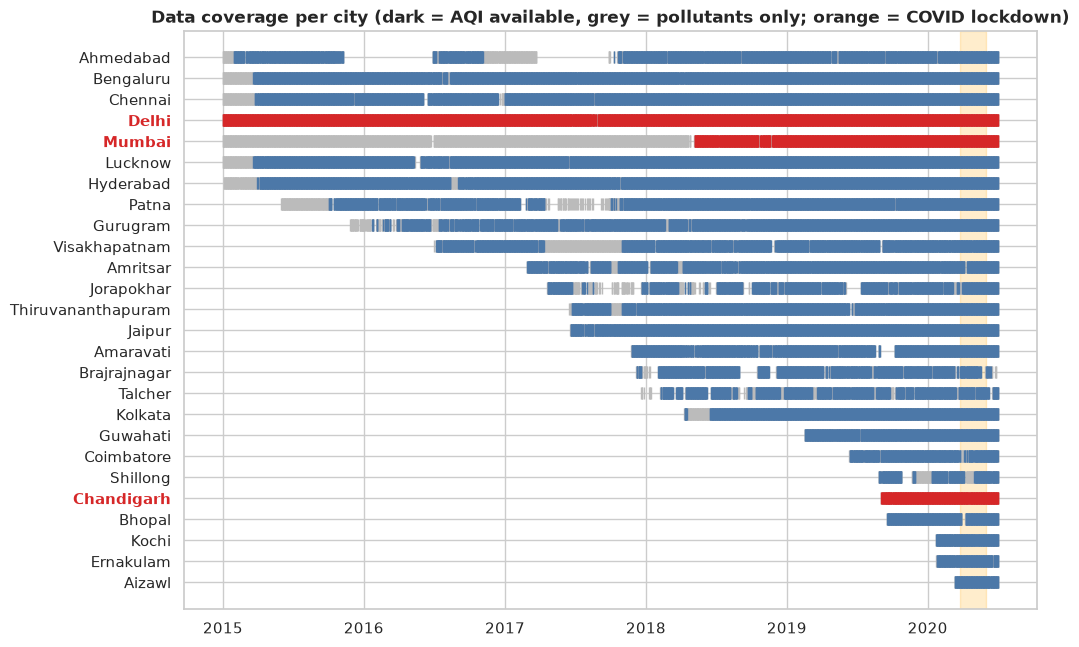

In [3]:
order = df.groupby("city")["date"].min().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 7.5))
for i, c in enumerate(order):
    g = df[df.city == c]
    ax.plot(g.date, np.full(len(g), i), "|", color="#bbbbbb", ms=9)
    ga = g[g.aqi.notna()]
    ax.plot(ga.date, np.full(len(ga), i), "|", color="#d62728" if c in CORE_CITIES else "#4c78a8", ms=9)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
for lbl in ax.get_yticklabels():
    if lbl.get_text() in CORE_CITIES: lbl.set_color("#d62728"); lbl.set_fontweight("bold")
ax.axvspan(pd.Timestamp(LOCKDOWN_START), pd.Timestamp(LOCKDOWN_END), color="orange", alpha=0.2)
ax.set_title("Data coverage per city (dark = AQI available, grey = pollutants only; orange = COVID lockdown)")
save_fig("03_coverage_timeline"); plt.show()
K["cities_full_history"] = int((cov.days > 1900).sum()); K["chandigarh_days"] = int(cov.loc["Chandigarh", "days"])

**Reading:** only **6 cities** (Delhi, Bengaluru, Hyderabad, Lucknow, Mumbai, Chennai) have ≈ 5.5 years of readings; many start in 2017–2020. Coverage therefore grows with time, which biases any naive pooled yearly average (we handle this by comparing like-for-like cities and periods below). **Chandigarh has only ~10 months** (Sept 2019 – Jul 2020); Mumbai has plenty of days but most of its AQI values are missing.

### 1.1 Distributions and outliers

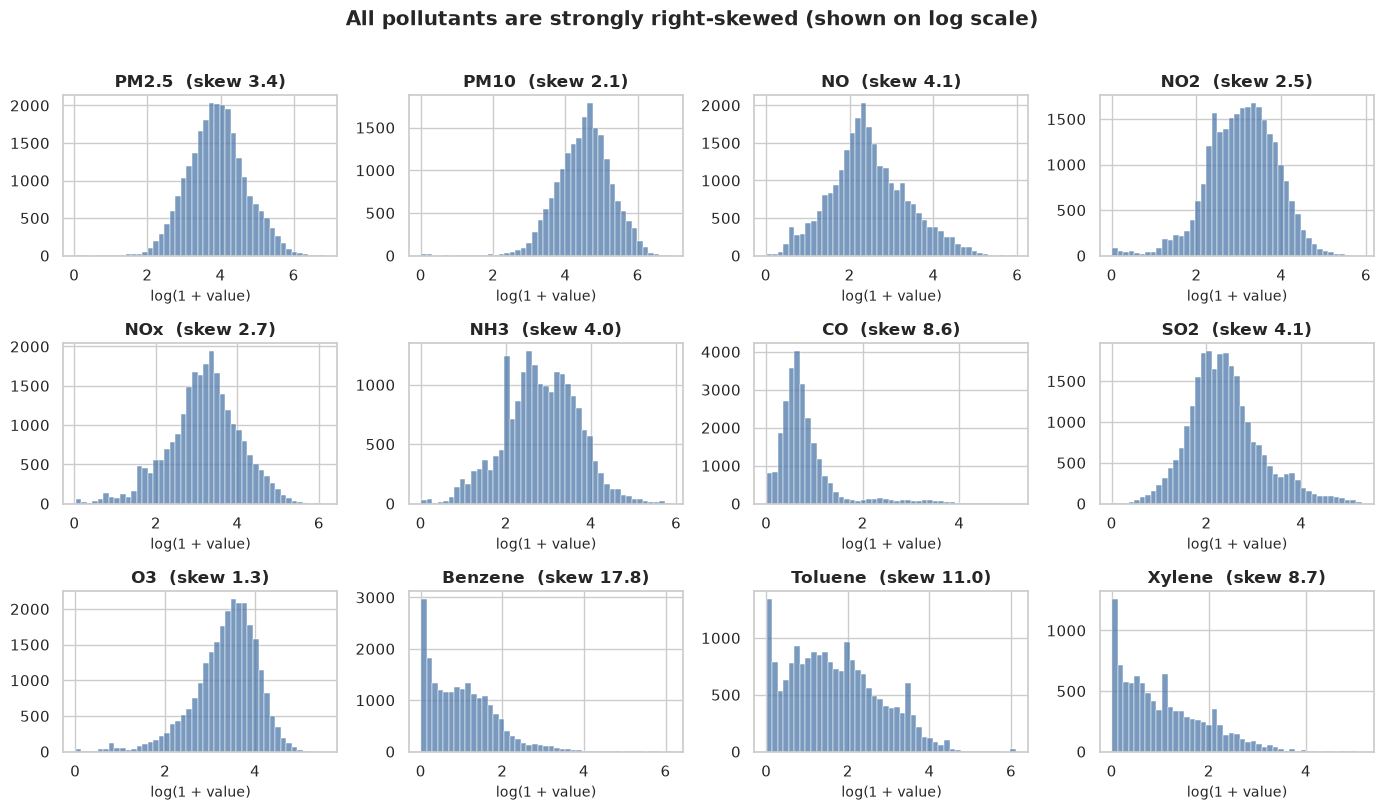

In [4]:
cols = MODEL_POLLUTANTS + ["xylene"]
fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for ax, c in zip(axes.ravel(), cols):
    x = np.log1p(df[c].dropna())
    sns.histplot(x, bins=45, ax=ax, color="#4c78a8"); ax.set_title(f"{LABELS[c]}  (skew {df[c].skew():.1f})"); ax.set_xlabel("log(1 + value)"); ax.set_ylabel("")
plt.suptitle("All pollutants are strongly right-skewed (shown on log scale)", y=1.01, fontweight="bold")
plt.tight_layout(); save_fig("03_pollutant_distributions"); plt.show()

In [5]:
desc = df[cols + ["aqi"]].describe(percentiles=[.5, .99]).T[["count", "mean", "50%", "99%", "max"]].round(1)
q1, q3 = df[cols + ["aqi"]].quantile(.25), df[cols + ["aqi"]].quantile(.75)
desc["% beyond Q3+3·IQR"] = (100 * (df[cols + ["aqi"]] > (q3 + 3 * (q3 - q1))).mean()).round(1)
desc.rename(index=LABELS)

,count,mean,50%,99%,max,% beyond Q3+3·IQR
PM2.5,25202.0,67.3,48.4,311.1,950.0,2.6
PM10,18693.0,118.2,95.6,444.7,1000.0,0.8
NO,26222.0,17.6,9.9,117.2,390.7,4.4
NO2,26216.0,28.4,21.6,117.1,362.2,1.0
NOx,24849.0,33.2,24.1,155.6,467.6,2.3
NH3,19511.0,23.5,15.9,130.6,352.9,1.5
CO,25569.0,2.4,1.0,35.4,175.8,6.5
SO2,26037.0,14.7,9.1,107.2,193.9,5.2
O3,25886.0,34.4,30.8,105.9,257.7,0.3
Benzene,21043.0,4.1,1.5,35.3,455.0,3.2


Extreme values are common (heavy right tails), but most are **real pollution episodes** (e.g. Delhi in November), not errors. We therefore **do not delete** outliers – we flag the impossible ones (above the 0–500 scale or at sensor ceilings, `is_outlier`) and use models that are robust to skew (tree ensembles) next to linear baselines.

### 1.2 The Ahmedabad anomaly

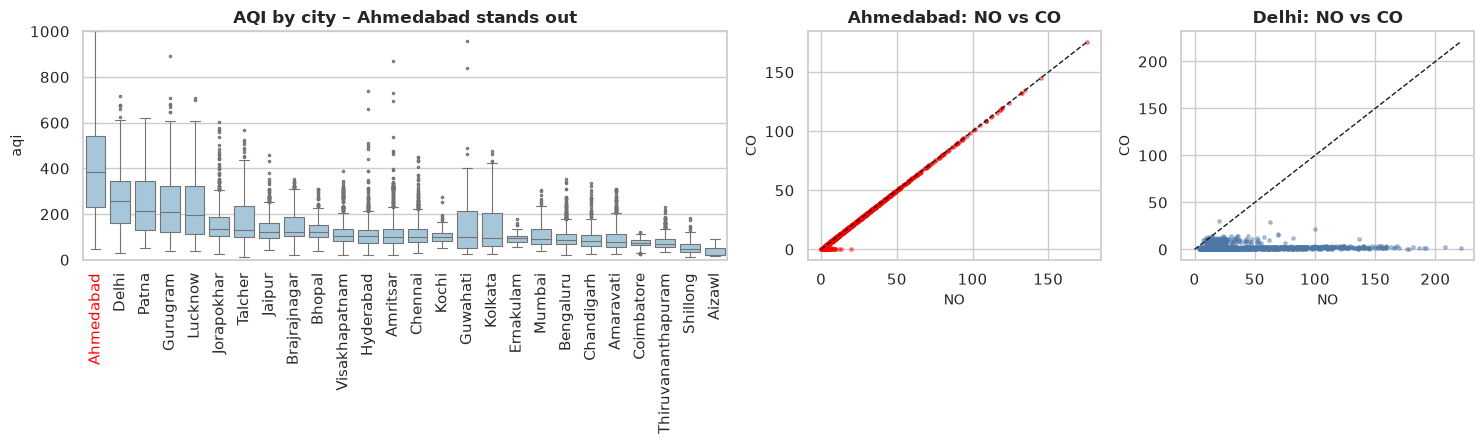

{'cities_full_history': 6, 'chandigarh_days': 304, 'ahmedabad_mean_aqi': np.float64(452.0), 'ahmedabad_no_eq_co_pct': np.float64(85.2), 'ahmedabad_share_of_above500': np.float64(76.0)}


In [6]:
order_c = df.groupby("city")["aqi"].median().sort_values(ascending=False).index
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [2.2, 1, 1]})
sns.boxplot(data=df, x="city", y="aqi", order=order_c, ax=axes[0], fliersize=1.5, color="#9ecae1", linewidth=0.8)
for lab in axes[0].get_xticklabels():
    lab.set_rotation(90)
    if lab.get_text() == "Ahmedabad": lab.set_color("red")
axes[0].set_ylim(0, 1000); axes[0].set_xlabel(""); axes[0].set_title("AQI by city – Ahmedabad stands out")
for ax, c in zip(axes[1:], ["Ahmedabad", "Delhi"]):
    g = df[df.city == c]
    ax.scatter(g.no_, g.co, s=6, alpha=0.4, color="red" if c == "Ahmedabad" else "#4c78a8")
    lim = max(g.no_.max(), g.co.max()); ax.plot([0, lim], [0, lim], "k--", lw=1); ax.set_xlabel("NO"); ax.set_ylabel("CO"); ax.set_title(f"{c}: NO vs CO")
plt.tight_layout(); save_fig("03_ahmedabad_anomaly"); plt.show()
ah = df[df.city == "Ahmedabad"]
K["ahmedabad_mean_aqi"] = round(ah.aqi.mean(), 0); K["ahmedabad_no_eq_co_pct"] = round(100 * ((ah.no_ == ah.co) & ah.no_.notna()).mean(), 1)
K["ahmedabad_share_of_above500"] = round(100 * (ah.aqi > 500).sum() / (df.aqi > 500).sum(), 0)
print(K)

Ahmedabad's NO and CO columns lie on the identity line (a copy-paste artefact) and its AQI is 2–4× higher than any other city, much of it above the official 500 cap. We **keep it in the database but exclude it from modelling and comparisons**; notebook 05 tests how much it changes the results.

## 2 · How polluted are the cities? AQI categories

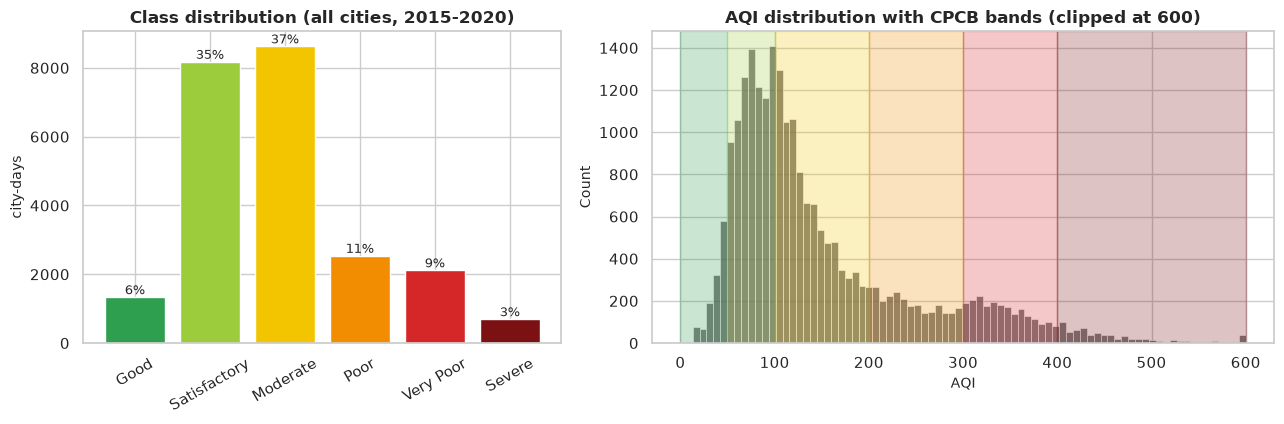

{'Good': 5.7, 'Satisfactory': 34.8, 'Moderate': 36.7, 'Poor': 10.8, 'Very Poor': 9.0, 'Severe': 3.0}


In [7]:
counts = ok["aqi_bucket"].value_counts().reindex(BUCKET_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].bar(counts.index, counts.values, color=[BUCKET_COLORS[b] for b in counts.index])
for i, v in enumerate(counts.values): axes[0].text(i, v + 80, f"{v / counts.sum():.0%}", ha="center", fontsize=9)
axes[0].set_title("Class distribution (all cities, 2015-2020)"); axes[0].set_ylabel("city-days"); plt.setp(axes[0].get_xticklabels(), rotation=30)
sns.histplot(ok["aqi"].clip(upper=600), bins=80, ax=axes[1], color="#555555")
for lo, hi, b in zip([0, 50, 100, 200, 300, 400], [50, 100, 200, 300, 400, 600], BUCKET_ORDER):
    axes[1].axvspan(lo, hi, color=BUCKET_COLORS[b], alpha=0.25)
axes[1].set_title("AQI distribution with CPCB bands (clipped at 600)"); axes[1].set_xlabel("AQI")
plt.tight_layout(); save_fig("03_aqi_distribution"); plt.show()
print((counts / counts.sum() * 100).round(1).to_dict()); K["class_share"] = (counts / counts.sum() * 100).round(1).to_dict()

The classes are **imbalanced** (Moderate and Satisfactory dominate; Good and Severe are rare) → for classification we must use class weights and report **macro-F1**, balanced accuracy and the confusion matrix, not just accuracy.

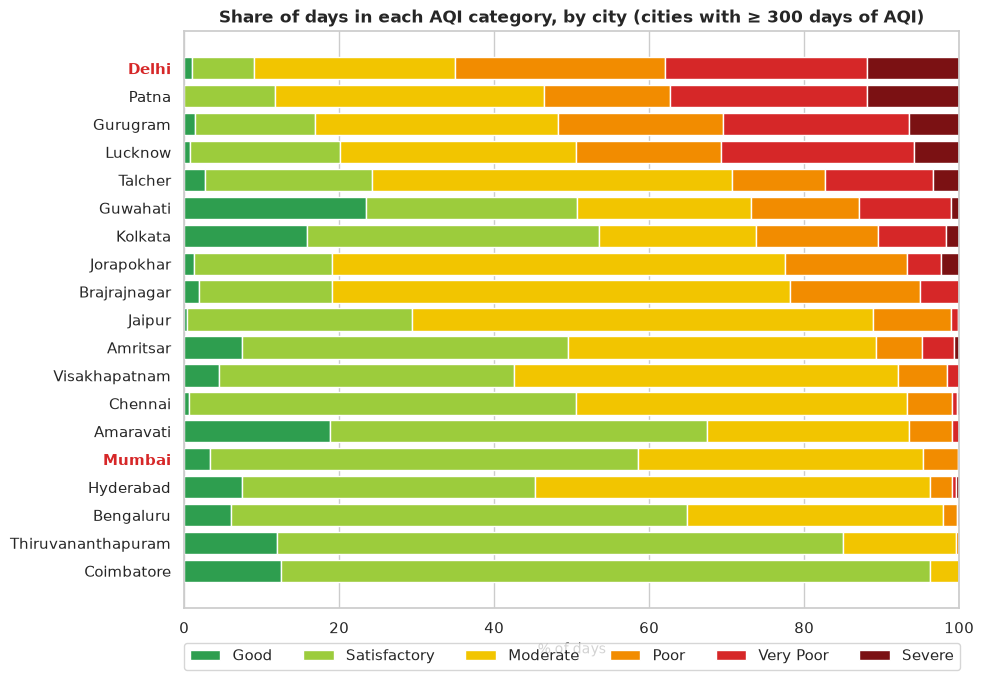

In [8]:
big = ok.groupby("city")["aqi"].count(); big = big[big >= 300].index        # at least 300 days with AQI
ct = pd.crosstab(ok.loc[ok.city.isin(big), "city"], ok.loc[ok.city.isin(big), "aqi_bucket"], normalize="index")[BUCKET_ORDER] * 100
ct = ct.assign(bad=ct[["Poor", "Very Poor", "Severe"]].sum(axis=1)).sort_values("bad").drop(columns="bad")
fig, ax = plt.subplots(figsize=(10, 7.5)); left = np.zeros(len(ct))
for b in BUCKET_ORDER:
    ax.barh(ct.index, ct[b], left=left, color=BUCKET_COLORS[b], label=b); left += ct[b].values
for lbl in ax.get_yticklabels():
    if lbl.get_text() in CORE_CITIES: lbl.set_fontweight("bold"); lbl.set_color("#d62728")
ax.set_xlabel("% of days"); ax.set_title("Share of days in each AQI category, by city (cities with ≥ 300 days of AQI)"); ax.legend(ncol=6, loc="lower center", bbox_to_anchor=(0.5, -0.12))
save_fig("03_bucket_share_by_city"); plt.show()

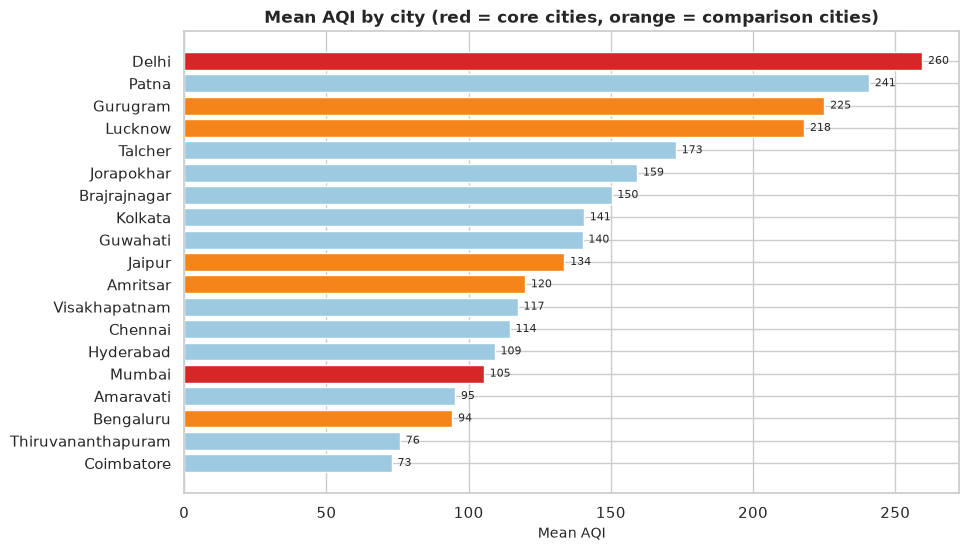

,days,mean,median,p90,max,pct_poor_or_worse
city,,,,,,
Delhi,1999,259.5,257.0,414.2,716.0,64.8
Patna,1459,240.8,215.0,407.0,619.0,45.7
Gurugram,1453,225.1,208.0,374.0,891.0,46.4
Lucknow,1893,218.0,198.0,373.0,707.0,47.0
Talcher,698,172.9,128.5,342.0,570.0,25.2
Jorapokhar,771,159.3,133.0,272.0,604.0,18.3
Brajrajnagar,713,150.3,122.0,271.6,355.0,19.6
Kolkata,754,140.6,94.0,318.8,475.0,24.3
Guwahati,495,140.1,98.0,308.6,956.0,26.5


In [9]:
cs = (ok.groupby("city")["aqi"].agg(days="count", mean="mean", median="median", p90=lambda s: s.quantile(.9), max="max")
        .assign(pct_poor_or_worse=ok.assign(bad=ok.aqi > 200).groupby("city")["bad"].mean() * 100).round(1))
cs = cs[cs.days >= 300].sort_values("mean", ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#d62728" if c in CORE_CITIES else ("#f58518" if c in COMPARE_CITIES else "#9ecae1") for c in cs.index]
ax.barh(cs.index[::-1], cs["mean"][::-1], color=colors[::-1]); ax.set_xlabel("Mean AQI")
ax.set_title("Mean AQI by city (red = core cities, orange = comparison cities)")
for i, v in enumerate(cs["mean"][::-1]): ax.text(v + 2, i, f"{v:.0f}", va="center", fontsize=8)
save_fig("03_mean_aqi_by_city"); plt.show()
K["worst_cities"] = cs.head(3)["mean"].round(0).to_dict(); K["cleanest_cities"] = cs.tail(3)["mean"].round(0).to_dict()
cs

,cities,mean_aqi,pm25,pm10,no2,so2,co
region,,,,,,,
North,6,199.5,95.3,170.2,32.6,11.4,1.5
East,5,183.8,84.9,137.8,25.7,21.3,1.5
Central,1,132.8,50.1,119.3,31.3,13.1,0.9
West,1,105.4,35.2,96.6,25.5,16.6,1.3
Northeast,3,103.9,47.9,82.6,8.7,11.3,0.5
South,9,101.6,41.0,79.4,23.8,8.7,1.1


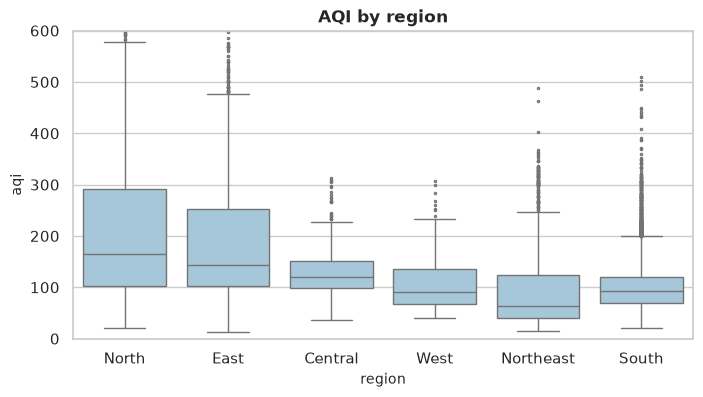

In [10]:
reg = ok.groupby("region").agg(cities=("city", "nunique"), mean_aqi=("aqi", "mean"), pm25=("pm25", "mean"), pm10=("pm10", "mean"),
                              no2=("no2", "mean"), so2=("so2", "mean"), co=("co", "mean")).round(1).sort_values("mean_aqi", ascending=False)
display(reg)
fig, ax = plt.subplots(figsize=(8, 4)); sns.boxplot(data=ok, x="region", y="aqi", order=reg.index, ax=ax, fliersize=1.5, color="#9ecae1"); ax.set_ylim(0, 600)
ax.set_title("AQI by region"); save_fig("03_aqi_by_region"); plt.show()

## 3 · Time-series EDA – yearly, monthly, weekday patterns

### 3.1 Yearly trend – compared like-for-like
Averaging all cities per year would be misleading (cities enter the data at different times, and 2020 stops in July). We use the seven long-history cities and compare **January–June only** in every year.

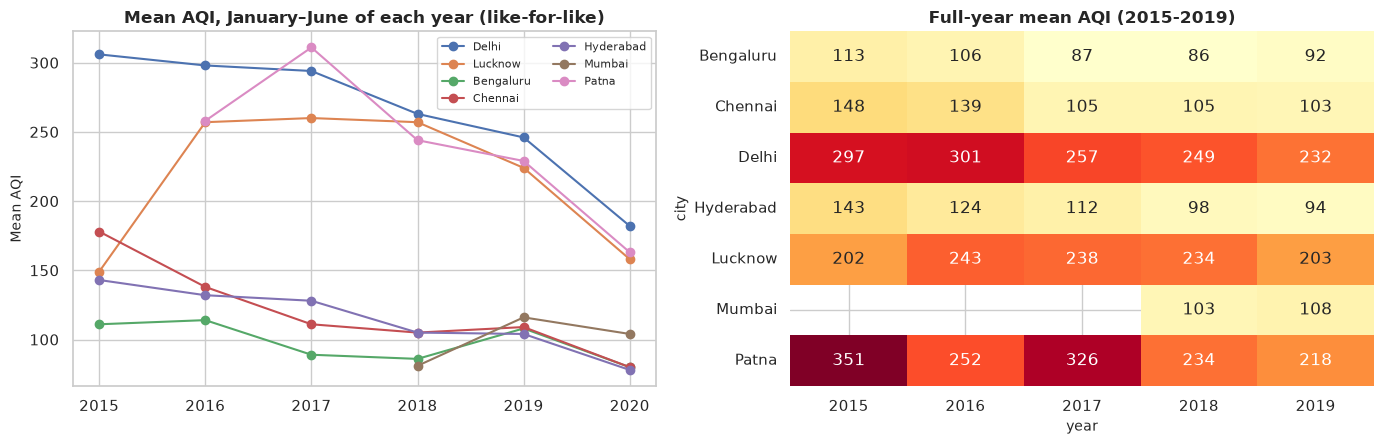

city,Bengaluru,Chennai,Delhi,Hyderabad,Lucknow,Mumbai,Patna
year,,,,,,,
2015,111.0,178.0,306.0,143.0,149.0,NaN,NaN
2016,114.0,138.0,298.0,132.0,257.0,NaN,258.0
2017,89.0,111.0,294.0,128.0,260.0,NaN,311.0
2018,86.0,105.0,263.0,105.0,257.0,81.0,244.0
2019,108.0,109.0,246.0,104.0,224.0,116.0,229.0
2020,80.0,80.0,182.0,78.0,158.0,104.0,163.0


In [11]:
long_cities = ["Delhi", "Lucknow", "Bengaluru", "Chennai", "Hyderabad", "Mumbai", "Patna"]
h1 = ok[(ok.city.isin(long_cities)) & (ok.month <= 6)]
yr = h1.pivot_table(index="year", columns="city", values="aqi", aggfunc="mean").round(0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for c in long_cities: axes[0].plot(yr.index, yr[c], marker="o", label=c)
axes[0].set_title("Mean AQI, January–June of each year (like-for-like)"); axes[0].set_ylabel("Mean AQI"); axes[0].legend(ncol=2, fontsize=8)
full_year = ok[(ok.city.isin(long_cities)) & (ok.year <= 2019)].pivot_table(index="year", columns="city", values="aqi", aggfunc="mean")
sns.heatmap(full_year.T.round(0), annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[1], cbar=False); axes[1].set_title("Full-year mean AQI (2015-2019)")
plt.tight_layout(); save_fig("03_yearly_trend"); plt.show()
yr

### 3.2 Seasonality – months

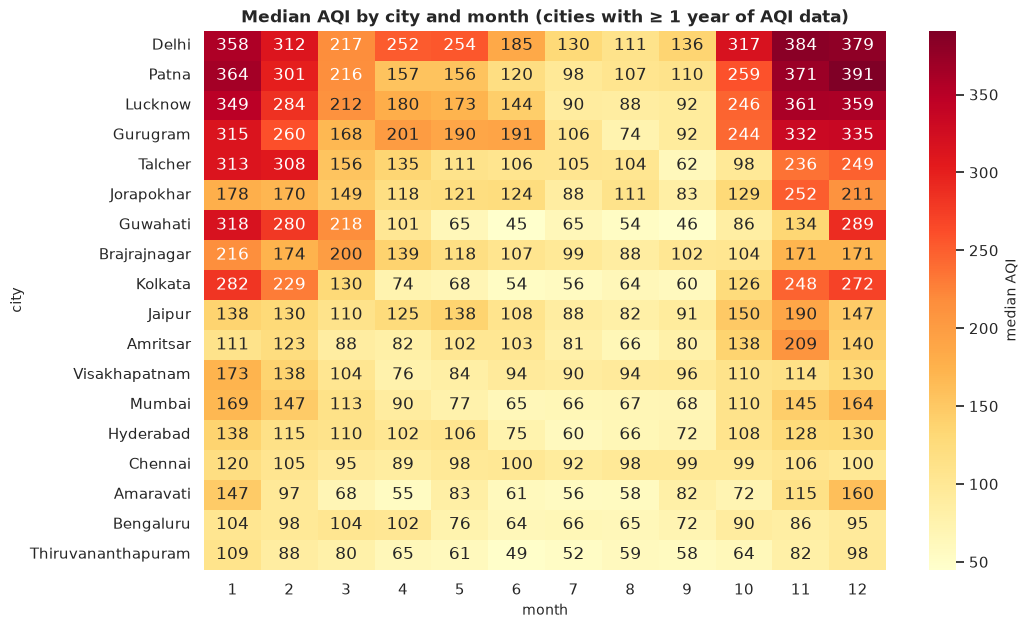

11 3.0 1.6


In [12]:
keep = ok.groupby("city")["aqi"].count(); keep = keep[keep >= 365].index
mon = ok[ok.city.isin(keep)].pivot_table(index="city", columns="month", values="aqi", aggfunc="median")
mon = mon.loc[mon.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(mon, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "median AQI"}, ax=ax)
ax.set_xlabel("month"); ax.set_title("Median AQI by city and month (cities with ≥ 1 year of AQI data)")
save_fig("03_month_heatmap"); plt.show()
north_m = ok[ok.city.isin(NORTH_CITIES)].groupby("month")["aqi"].mean(); south_m = ok[ok.region == "South"].groupby("month")["aqi"].mean()
K["north_peak_month"] = int(north_m.idxmax()); K["north_peak_vs_trough"] = round(north_m.max() / north_m.min(), 1)
K["south_peak_vs_trough"] = round(south_m.max() / south_m.min(), 1); print(K["north_peak_month"], K["north_peak_vs_trough"], K["south_peak_vs_trough"])

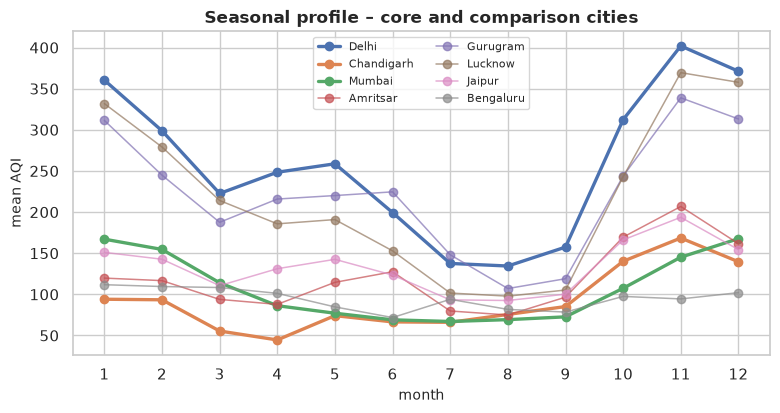

,mean,median,count
season,,,
Winter,204.0,163.0,5951
Summer,134.5,112.0,6721
Monsoon,100.3,86.0,7246
Post-monsoon,191.4,145.0,3598


In [13]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for c in COMPARE_CITIES:
    g = ok[ok.city == c].groupby("month")["aqi"].mean()
    ax.plot(g.index, g.values, marker="o", lw=2.4 if c in CORE_CITIES else 1.1, label=c, alpha=1 if c in CORE_CITIES else 0.7)
ax.set_xticks(range(1, 13)); ax.set_xlabel("month"); ax.set_ylabel("mean AQI"); ax.legend(ncol=2, fontsize=8); ax.set_title("Seasonal profile – core and comparison cities")
save_fig("03_seasonal_profile_core"); plt.show()
sea = ok.groupby("season")["aqi"].agg(["mean", "median", "count"]).round(1).loc[["Winter", "Summer", "Monsoon", "Post-monsoon"]]; sea

### 3.3 Daily time series – Delhi, Chandigarh, Mumbai

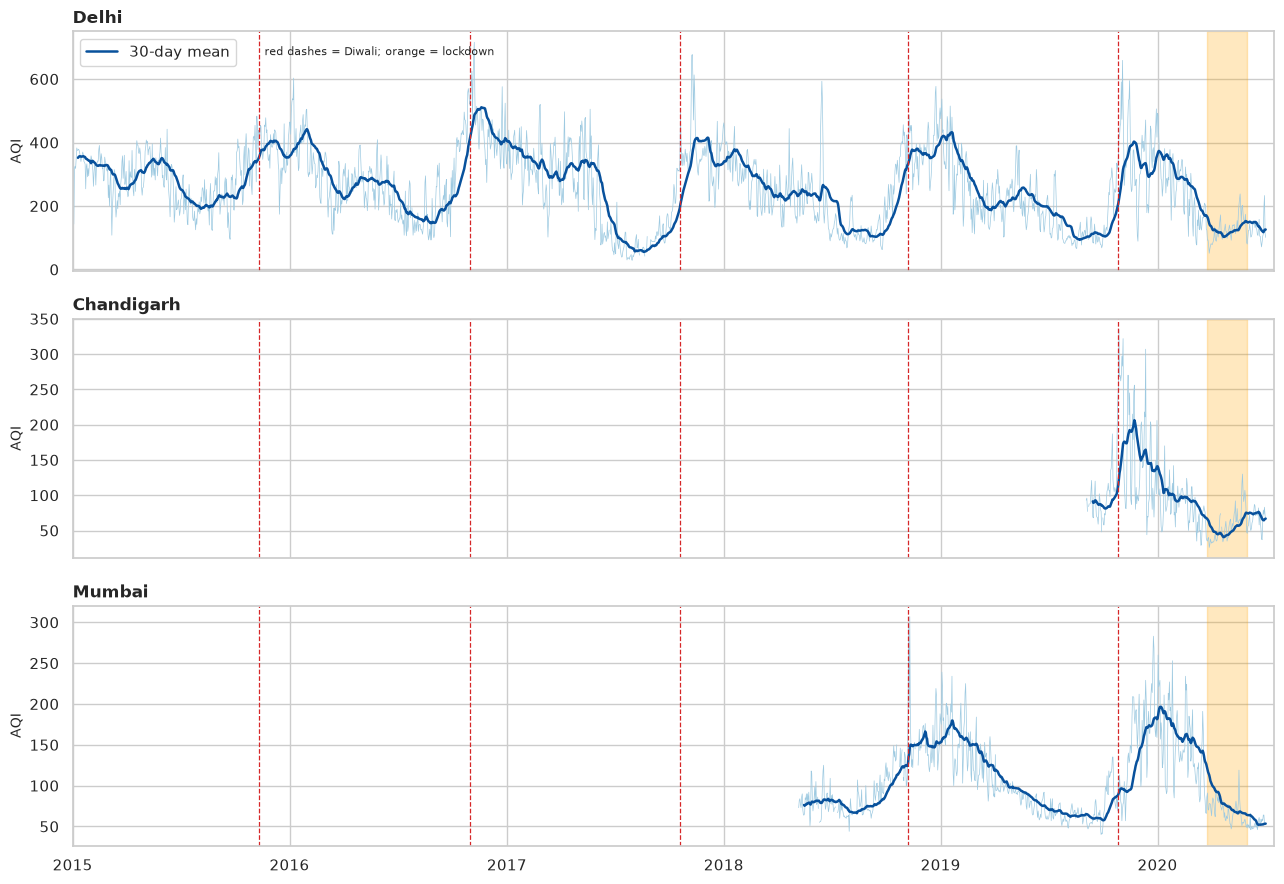

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, c in zip(axes, CORE_CITIES):
    g = ok[ok.city == c].set_index("date")["aqi"].asfreq("D")
    ax.plot(g.index, g.values, lw=0.5, color="#9ecae1"); ax.plot(g.index, g.rolling(30, min_periods=10).mean(), lw=1.8, color="#08519c", label="30-day mean")
    for d in FESTIVALS["Diwali"]: ax.axvline(pd.Timestamp(d), color="#d62728", ls="--", lw=0.9)
    ax.axvspan(pd.Timestamp(LOCKDOWN_START), pd.Timestamp(LOCKDOWN_END), color="orange", alpha=0.25)
    ax.set_ylabel("AQI"); ax.set_title(c, loc="left")
axes[0].legend(loc="upper left"); axes[0].text(pd.Timestamp("2015-11-20"), axes[0].get_ylim()[1] * 0.9, "red dashes = Diwali; orange = lockdown", fontsize=8)
axes[-1].set_xlim(pd.Timestamp("2015-01-01"), pd.Timestamp("2020-07-15")); plt.tight_layout(); save_fig("03_timeseries_core_cities"); plt.show()

### 3.4 Weekday effect
Weekday differences are small compared with seasonal swings, so we remove seasonality first (AQI minus its city-month mean) and then average by weekday.

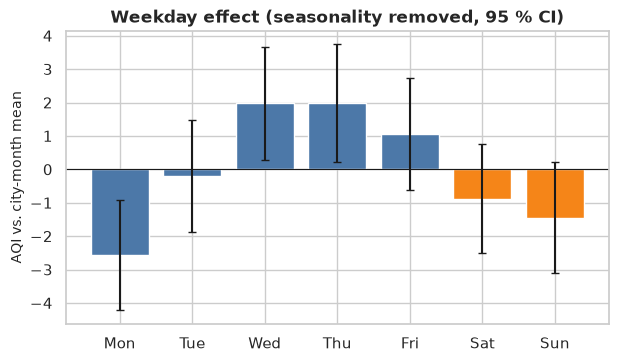

weekend − weekday = -1.64 AQI points (Mann-Whitney p = 0.0512); largest weekday swing 4.6 points


In [15]:
w = ok[ok.aqi.notna()].copy()
w["rel"] = w["aqi"] - w.groupby(["city", "year", "month"])["aqi"].transform("mean")
wk = w.groupby("dayofweek")["rel"].agg(["mean", "sem", "count"]); names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.bar(names, wk["mean"], yerr=1.96 * wk["sem"], color=["#4c78a8"] * 5 + ["#f58518"] * 2, capsize=3)
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("AQI vs. city-month mean"); ax.set_title("Weekday effect (seasonality removed, 95 % CI)")
save_fig("03_weekday_effect"); plt.show()
wkend = w[w.is_weekend == 1]["rel"]; wkday = w[w.is_weekend == 0]["rel"]
u = stats.mannwhitneyu(wkend, wkday); K["weekend_effect"] = round(wkend.mean() - wkday.mean(), 2); K["weekend_p"] = float(u.pvalue)
print(f"weekend − weekday = {K['weekend_effect']:+.2f} AQI points (Mann-Whitney p = {u.pvalue:.3g}); largest weekday swing {wk['mean'].max() - wk['mean'].min():.1f} points")

## 4 · Pollutants – relationships and drivers

### 4.1 Correlation matrix (Spearman – robust to skew)

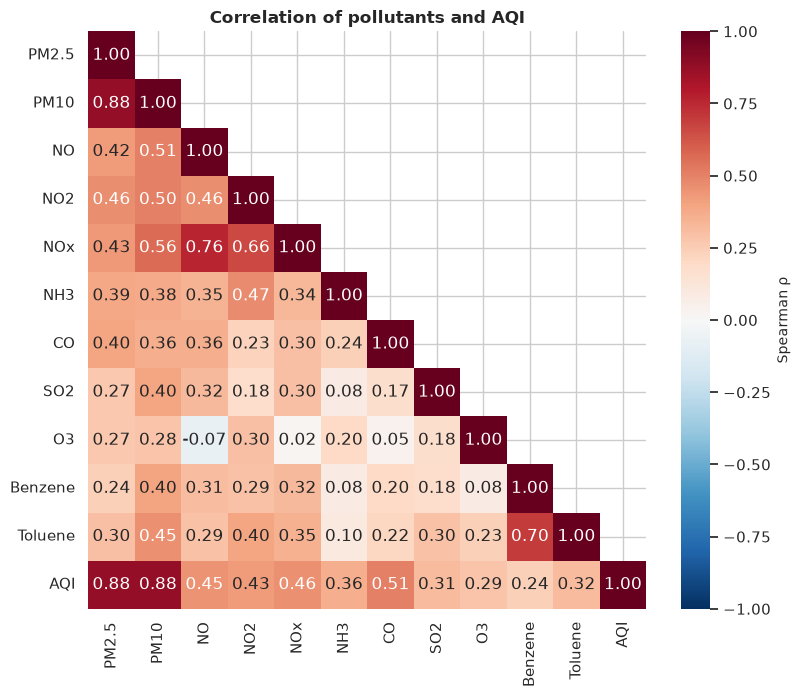

Strongly related pollutant pairs (|ρ| > 0.7):


,a,b,rho
12,PM10,PM2.5,0.88
50,NOx,NO,0.76
129,Toluene,Benzene,0.70


{'PM10': 0.88, 'PM2.5': 0.88, 'CO': 0.51, 'NOx': 0.46, 'NO': 0.45, 'NO2': 0.43, 'NH3': 0.36, 'Toluene': 0.32, 'SO2': 0.31, 'O3': 0.29, 'Benzene': 0.24}


In [16]:
cm = ok[MODEL_POLLUTANTS + ["aqi"]].corr(method="spearman").rename(index=LABELS, columns=LABELS)
mask = np.triu(np.ones_like(cm, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7.5)); sns.heatmap(cm, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman ρ"})
ax.set_title("Correlation of pollutants and AQI"); save_fig("03_correlation_heatmap"); plt.show()
pairs = cm.where(~mask & (cm.abs() < 0.9999)).stack().rename("rho").reset_index(); pairs.columns = ["a", "b", "rho"]
strong = pairs[(pairs.a != "AQI") & (pairs.b != "AQI") & (pairs.rho.abs() > 0.7)].sort_values("rho", ascending=False)
print("Strongly related pollutant pairs (|ρ| > 0.7):"); display(strong.round(2))
K["corr_with_aqi"] = cm["AQI"].drop("AQI").sort_values(ascending=False).round(2).to_dict(); print(K["corr_with_aqi"])

### 4.2 PM versus AQI, and PM2.5/PM10 ratio

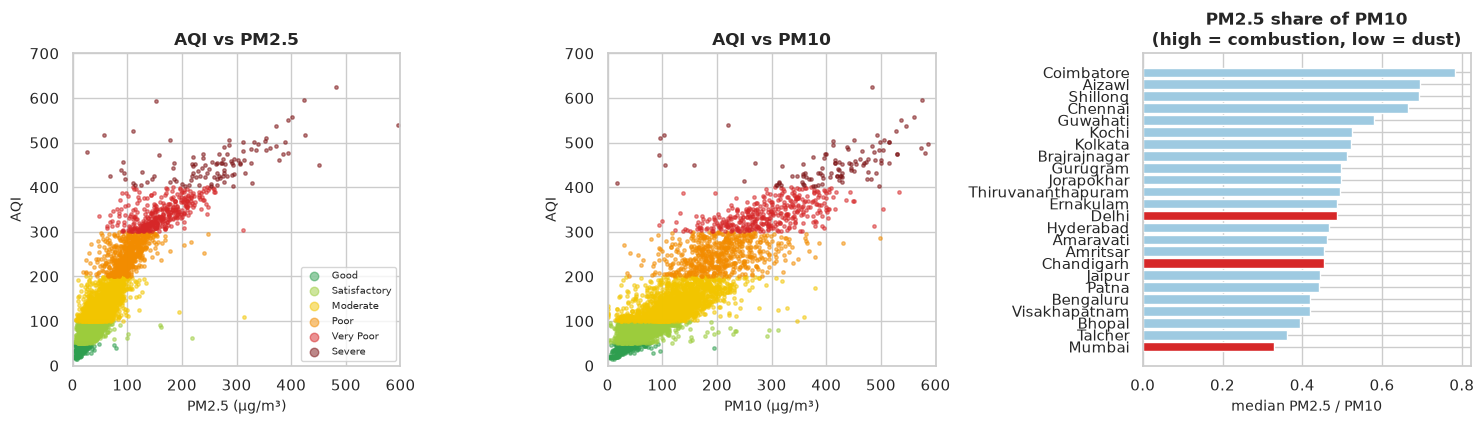

In [17]:
s = ok.dropna(subset=["aqi", "pm25", "pm10"]).sample(6000, random_state=1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, c in zip(axes[:2], ["pm25", "pm10"]):
    for b in BUCKET_ORDER:
        t = s[s.aqi_bucket == b]; ax.scatter(t[c], t["aqi"], s=6, alpha=0.5, color=BUCKET_COLORS[b], label=b)
    ax.set_xlabel(f"{LABELS[c]} (µg/m³)"); ax.set_ylabel("AQI"); ax.set_title(f"AQI vs {LABELS[c]}"); ax.set_xlim(0, 600); ax.set_ylim(0, 700)
axes[0].legend(markerscale=2.5, fontsize=7)
ratio = (ok.dropna(subset=["pm25", "pm10"]).assign(r=lambda d: d.pm25 / d.pm10).groupby("city")["r"].agg(["median", "count"]))
ratio = ratio[ratio["count"] >= 100].sort_values("median")
axes[2].barh(ratio.index, ratio["median"], color=["#d62728" if c in CORE_CITIES else "#9ecae1" for c in ratio.index]); axes[2].set_xlabel("median PM2.5 / PM10")
axes[2].set_title("PM2.5 share of PM10\n(high = combustion, low = dust)")
plt.tight_layout(); save_fig("03_pm_vs_aqi"); plt.show()

### 4.3 Which pollutant sets the AQI? (CPCB sub-index re-computation)

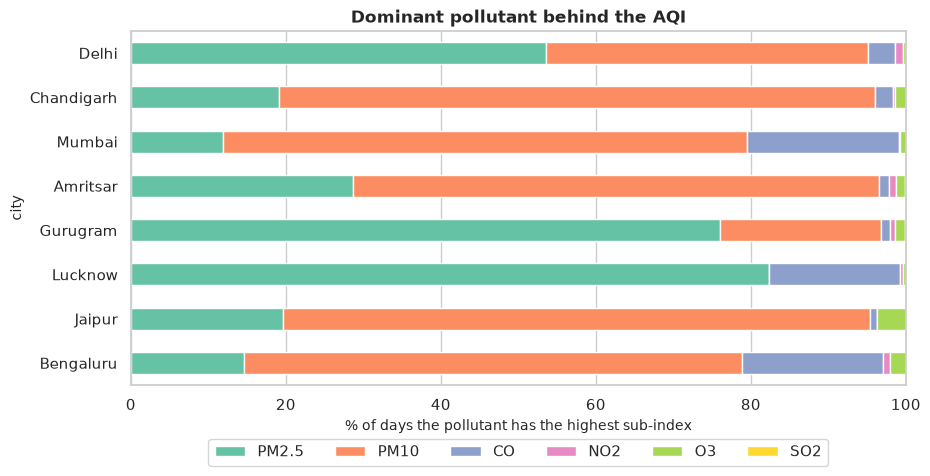

dominant,PM2.5,PM10,CO,NO2,O3,SO2
city,,,,,,
Delhi,54.0,42.0,4.0,1.0,0.0,0.0
Chandigarh,19.0,77.0,2.0,0.0,1.0,0.0
Mumbai,12.0,68.0,20.0,0.0,1.0,0.0
Amritsar,29.0,68.0,1.0,1.0,1.0,0.0
Gurugram,76.0,21.0,1.0,1.0,1.0,0.0
Lucknow,82.0,0.0,17.0,0.0,0.0,0.0
Jaipur,20.0,76.0,1.0,0.0,4.0,0.0
Bengaluru,15.0,64.0,18.0,1.0,2.0,0.0


In [18]:
rec = ok.copy(); rec["aqi_cpcb"], rec["dominant"] = cpcb.reconstruct_aqi(rec)
sel = rec[rec.aqi.notna() & rec.dominant.notna() & rec.city.isin(COMPARE_CITIES)]
dom = pd.crosstab(sel.city, sel.dominant, normalize="index").mul(100).rename(columns=LABELS)
dom = dom[[c for c in ["PM2.5", "PM10", "CO", "NO2", "O3", "SO2", "NH3"] if c in dom.columns]].loc[COMPARE_CITIES]
ax = dom.plot.barh(stacked=True, figsize=(10, 4.6), color=sns.color_palette("Set2", len(dom.columns))); ax.invert_yaxis()
ax.set_xlabel("% of days the pollutant has the highest sub-index"); ax.set_title("Dominant pollutant behind the AQI"); ax.legend(ncol=7, loc="lower center", bbox_to_anchor=(0.5, -0.25))
save_fig("03_dominant_pollutant"); plt.show()
dom.round(0)

## 5 · Festival effects, stubble burning, and the COVID lockdown

### 5.1 Diwali – event study
For each city-year we divide AQI by the city's **baseline** (mean of days −10…−4 before Diwali) and average over city-years. Values > 1 mean "worse than the quiet week before".
Diwali dates come from `src/config.py` (please verify them against an official calendar).

59 city-year Diwali observations


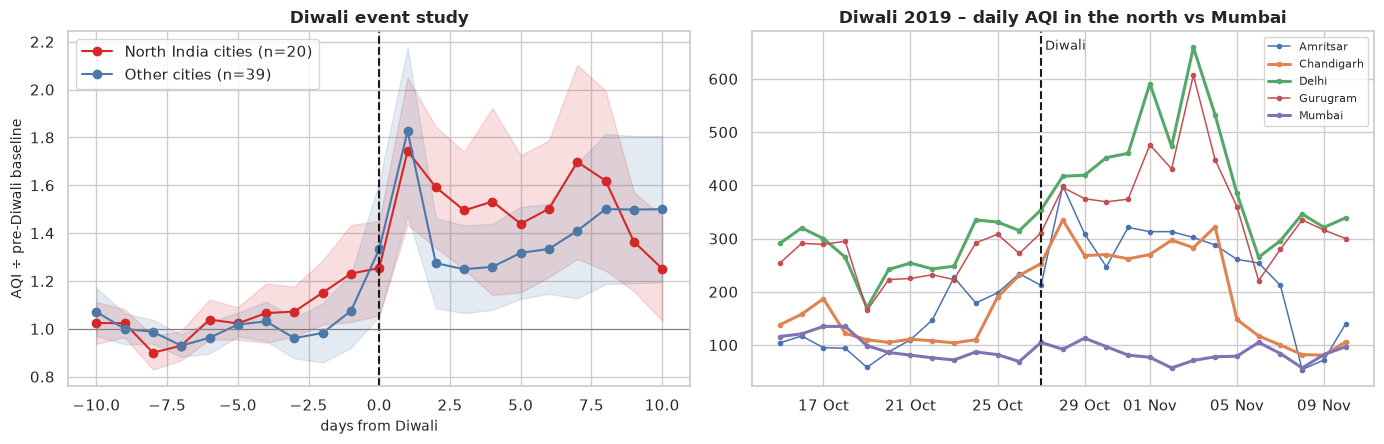

In [19]:
def event_table(dates, cities, base=(-10, -4), win=(-1, 3)):
    """For each city and event date: mean AQI in the event window vs. the baseline days before it."""
    rows, curve = [], []
    for city in cities:
        g = ok[(ok.city == city) & ok.aqi.notna()].set_index("date")["aqi"]
        for d in pd.to_datetime(list(dates)):
            s = g[(g.index >= d - pd.Timedelta(days=10)) & (g.index <= d + pd.Timedelta(days=10))]
            rel = (s.index - d).days
            b = s[(rel >= base[0]) & (rel <= base[1])]; wv = s[(rel >= win[0]) & (rel <= win[1])]
            if len(b) < 4 or len(wv) < 2: continue
            rows.append(dict(city=city, date=d.date(), baseline=b.mean(), window=wv.mean(), pct_chg=(wv.mean() / b.mean() - 1) * 100))
            curve.append(pd.DataFrame({"city": city, "fdate": d, "rel_day": rel, "ratio": s.values / b.mean()}))
    return pd.DataFrame(rows), (pd.concat(curve) if curve else pd.DataFrame())

all_cities = list(ok.city.unique())
dw_tab, dw_curve = event_table(FESTIVALS["Diwali"], all_cities)
dw_tab["north"] = dw_tab.city.isin(NORTH_CITIES); dw_curve["north"] = dw_curve.city.isin(NORTH_CITIES)
print(f"{len(dw_tab)} city-year Diwali observations")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for flag, lab, col in [(True, "North India cities", "#d62728"), (False, "Other cities", "#4c78a8")]:
    c = dw_curve[dw_curve.north == flag].groupby("rel_day")["ratio"].agg(["mean", "sem"])
    axes[0].plot(c.index, c["mean"], marker="o", color=col, label=f"{lab} (n={dw_tab[dw_tab.north == flag].shape[0]})"); axes[0].fill_between(c.index, c["mean"] - 1.96 * c["sem"], c["mean"] + 1.96 * c["sem"], color=col, alpha=0.15)
axes[0].axvline(0, color="k", ls="--"); axes[0].axhline(1, color="grey", lw=0.8); axes[0].set_xlabel("days from Diwali"); axes[0].set_ylabel("AQI ÷ pre-Diwali baseline"); axes[0].legend(); axes[0].set_title("Diwali event study")
d19 = ok[(ok.city.isin(["Delhi", "Chandigarh", "Amritsar", "Gurugram", "Mumbai"])) & (ok.date.between("2019-10-15", "2019-11-10"))]
for c, g in d19.groupby("city"): axes[1].plot(g.date, g.aqi, marker=".", lw=2.2 if c in CORE_CITIES else 1.1, label=c)
axes[1].axvline(pd.Timestamp("2019-10-27"), color="k", ls="--"); axes[1].text(pd.Timestamp("2019-10-27"), axes[1].get_ylim()[1] * 0.95, " Diwali", fontsize=9); axes[1].legend(fontsize=8)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); axes[1].set_title("Diwali 2019 – daily AQI in the north vs Mumbai")
plt.tight_layout(); save_fig("03_diwali_event_study"); plt.show()

**Careful – seasonality confounds festival effects.** AQI rises on its own from September to November and falls from February to May. So "AQI after the festival vs before" mixes the festival with the seasonal drift. We therefore run a **placebo test**: the *same* statistic computed for dates shifted by ±30 days (when no festival happens). The festival's **excess effect** = real change − placebo change.

In [20]:
def festival_test(name, dates, win, cities=all_cities):
    real, _ = event_table(dates, cities, win=win)
    plc = pd.concat([event_table([pd.Timestamp(d) + pd.Timedelta(days=k) for d in dates], cities, win=win)[0] for k in (-30, 30)])
    excess = real.pct_chg.mean() - plc.pct_chg.mean()
    p = stats.mannwhitneyu(real.pct_chg, plc.pct_chg, alternative="greater").pvalue
    return {"event": name, "n_real": len(real), "real_%_change": round(real.pct_chg.mean(), 1), "n_placebo": len(plc),
            "placebo_%_change": round(plc.pct_chg.mean(), 1), "excess_effect_pts": round(excess, 1), "p_value(real>placebo)": float(p)}

north_ok = [c for c in all_cities if c in NORTH_CITIES]; other_ok = [c for c in all_cities if c not in NORTH_CITIES]
rows = [festival_test("Diwali – all cities", FESTIVALS["Diwali"], (-1, 3)),
        festival_test("Diwali – north India", FESTIVALS["Diwali"], (-1, 3), north_ok),
        festival_test("Diwali – other cities", FESTIVALS["Diwali"], (-1, 3), other_ok),
        festival_test("Holi", FESTIVALS["Holi"], (-1, 1)),
        festival_test("Dussehra", FESTIVALS["Dussehra"], (-1, 1))]
summ = pd.DataFrame(rows); K["festival_summary"] = summ.to_dict("records")
summ["p_value(real>placebo)"] = summ["p_value(real>placebo)"].map(lambda p: f"{p:.2g}")
display(summ)
display(dw_tab[dw_tab.city.isin(CORE_CITIES + ["Amritsar", "Gurugram", "Lucknow"])].round(0).sort_values(["city", "date"]).reset_index(drop=True))

,event,n_real,real_%_change,n_placebo,placebo_%_change,excess_effect_pts,p_value(real>placebo)
0,Diwali – all cities,59,37.8,114,4.8,33.0,4.1e-06
1,Diwali – north India,20,46.3,42,-5.7,52.0,9.2e-06
2,Diwali – other cities,39,33.5,72,11.0,22.5,0.012
3,Holi,68,-9.4,135,-2.8,-6.6,0.95
4,Dussehra,54,36.5,109,10.5,26.0,0.00016


,city,date,baseline,window,pct_chg,north
0,Amritsar,2018-11-07,149.0,139.0,-7.0,True
1,Amritsar,2019-10-27,117.0,280.0,140.0,True
2,Chandigarh,2019-10-27,121.0,271.0,124.0,True
3,Delhi,2015-11-11,406.0,439.0,8.0,True
4,Delhi,2016-10-30,447.0,548.0,23.0,True
5,Delhi,2017-10-19,260.0,377.0,45.0,True
6,Delhi,2018-11-07,408.0,419.0,3.0,True
7,Delhi,2019-10-27,246.0,391.0,59.0,True
8,Gurugram,2016-10-30,149.0,410.0,175.0,True
9,Gurugram,2017-10-19,168.0,329.0,96.0,True


### 5.2 Stubble-burning season (15 Oct – 30 Nov) — a difference-in-differences style comparison
Autumn naturally brings worse air everywhere (monsoon ends). To isolate the *extra* rise in the paddy-burning belt we compare the change from 1 Sep–14 Oct to 15 Oct–30 Nov in north India versus other regions.

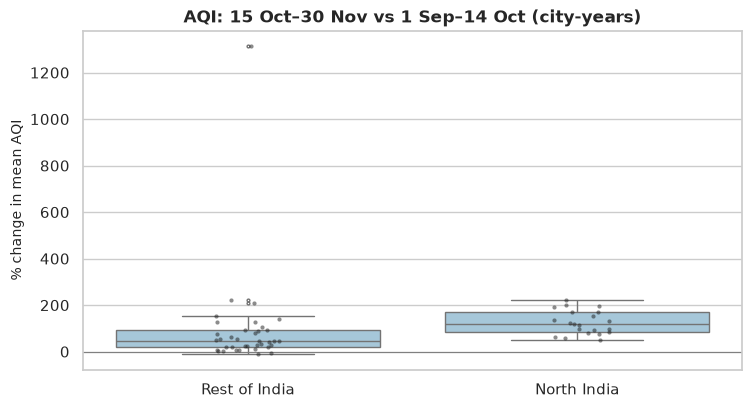

North India: +125% (n=21)   Rest of India: +94% (n=37)   Mann-Whitney p = 0.00019


In [21]:
def season_change(g):
    a = g[(g.month == 9) | ((g.month == 10) & (g.dayofweek >= 0) & (g.date.dt.day < 15))]["aqi"].mean()
    b = g[((g.month == 10) & (g.date.dt.day >= 15)) | (g.month == 11)]["aqi"].mean()
    return pd.Series({"before": a, "season": b, "pct_chg": (b / a - 1) * 100})
rows = []
for (city, yr_), g in ok[(ok.year <= 2019) & ok.aqi.notna()].groupby(["city", "year"]):
    if g[g.month.isin([9, 10, 11])].shape[0] >= 60: rows.append(season_change(g).to_frame().T.assign(city=city, year=yr_, region=g.region.iloc[0]))
sb = pd.concat(rows, ignore_index=True)
sb["group"] = np.where(sb.city.isin(NORTH_CITIES), "North India", "Rest of India")
fig, ax = plt.subplots(figsize=(8.5, 4.4)); sns.boxplot(data=sb, x="group", y="pct_chg", ax=ax, color="#9ecae1", fliersize=2); sns.stripplot(data=sb, x="group", y="pct_chg", ax=ax, color="k", size=3, alpha=0.5)
ax.axhline(0, color="grey", lw=0.8); ax.set_ylabel("% change in mean AQI"); ax.set_xlabel(""); ax.set_title("AQI: 15 Oct–30 Nov vs 1 Sep–14 Oct (city-years)")
save_fig("03_stubble_season"); plt.show()
g_n, g_o = sb[sb.group == "North India"].pct_chg.astype(float), sb[sb.group != "North India"].pct_chg.astype(float)
K["stubble_north_mean"] = round(g_n.mean(), 0); K["stubble_other_mean"] = round(g_o.mean(), 0); K["stubble_p"] = float(stats.mannwhitneyu(g_n, g_o).pvalue)
print(f"North India: {g_n.mean():+.0f}% (n={len(g_n)})   Rest of India: {g_o.mean():+.0f}% (n={len(g_o)})   Mann-Whitney p = {K['stubble_p']:.2g}")

### 5.3 COVID-19 lockdown – a natural experiment
India's strict lockdown began on 25 March 2020. We compare **25 Mar – 31 May 2020 with the same dates in 2019** for every city that has both.

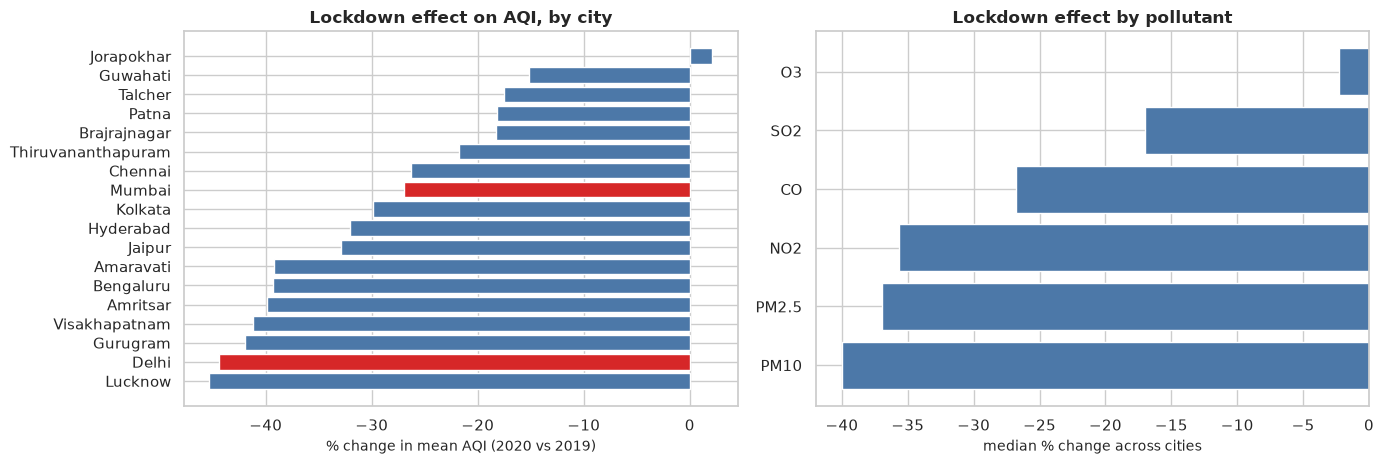

-31.0 {'PM2.5': np.float64(-37.0), 'PM10': np.float64(-40.0), 'NO2': np.float64(-36.0), 'SO2': np.float64(-17.0), 'CO': np.float64(-27.0), 'O3': np.float64(-2.0)} {'Delhi': -44.0, 'Mumbai': -27.0}


,aqi_2019,aqi_2020,n19,n20,pct_chg
city,,,,,
Lucknow,204.6,111.9,68.0,68,-45.3
Delhi,225.5,125.4,68.0,68,-44.4
Gurugram,212.4,123.3,68.0,68,-41.9
Visakhapatnam,106.8,62.8,66.0,66,-41.2
Amritsar,114.6,68.8,68.0,62,-39.9
Bengaluru,116.2,70.6,68.0,68,-39.3
Amaravati,88.8,54.0,64.0,68,-39.2
Jaipur,143.8,96.5,68.0,68,-32.9
Hyderabad,105.6,71.8,68.0,68,-32.1


In [22]:
win = lambda y: ok[ok.date.between(f"{y}-03-25", f"{y}-05-31")]
a19, a20 = win(2019), win(2020)
lc = pd.DataFrame({"aqi_2019": a19.groupby("city")["aqi"].mean(), "aqi_2020": a20.groupby("city")["aqi"].mean(),
                   "n19": a19.groupby("city")["aqi"].count(), "n20": a20.groupby("city")["aqi"].count()}).dropna()
lc = lc[(lc.n19 >= 30) & (lc.n20 >= 30)]; lc["pct_chg"] = (lc.aqi_2020 / lc.aqi_2019 - 1) * 100; lc = lc.sort_values("pct_chg")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].barh(lc.index, lc.pct_chg, color=["#d62728" if c in CORE_CITIES else "#4c78a8" for c in lc.index]); axes[0].set_xlabel("% change in mean AQI (2020 vs 2019)"); axes[0].set_title("Lockdown effect on AQI, by city")
pol_change = {}
for p in ["pm25", "pm10", "no2", "so2", "co", "o3"]:
    r = (a20.groupby("city")[p].mean() / a19.groupby("city")[p].mean() - 1).dropna() * 100
    r = r[r.index.isin(lc.index)]; pol_change[LABELS[p]] = r.median()
pc = pd.Series(pol_change).sort_values(); axes[1].barh(pc.index, pc.values, color=["#4c78a8" if v < 0 else "#f58518" for v in pc.values])
axes[1].set_xlabel("median % change across cities"); axes[1].set_title("Lockdown effect by pollutant")
plt.tight_layout(); save_fig("03_lockdown_effect"); plt.show()
K["lockdown_median_aqi_change"] = round(lc.pct_chg.median(), 0); K["lockdown_cities"] = int(len(lc)); K["lockdown_pollutant_change"] = {k: round(v, 0) for k, v in pol_change.items()}
K["lockdown_core"] = lc.loc[[c for c in CORE_CITIES if c in lc.index], "pct_chg"].round(0).to_dict()
print(K["lockdown_median_aqi_change"], K["lockdown_pollutant_change"], K["lockdown_core"])
lc.round(1)

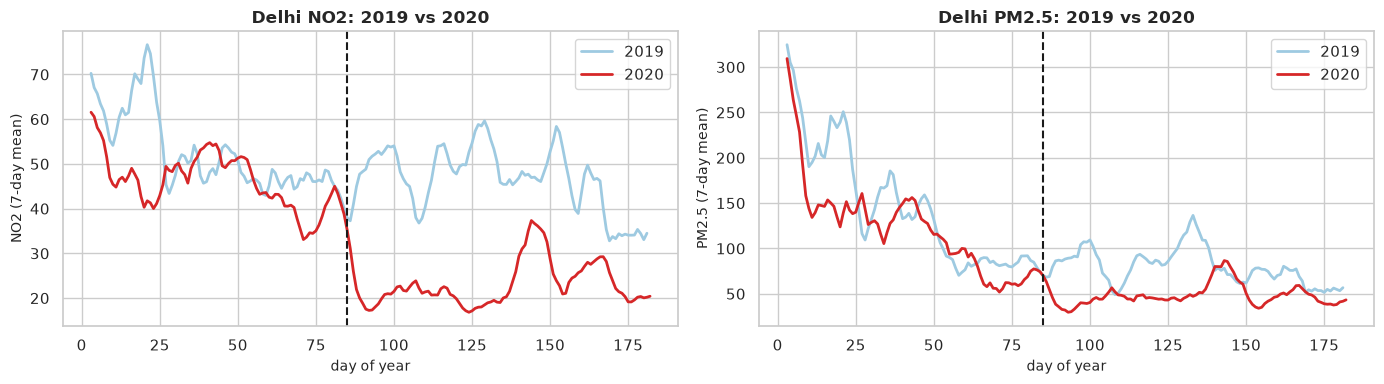

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, p in zip(axes, ["no2", "pm25"]):
    for yr_, col in [(2019, "#9ecae1"), (2020, "#d62728")]:
        g = ok[(ok.city == "Delhi") & (ok.year == yr_) & (ok.month <= 6)].set_index("date")[p]
        ax.plot(g.index.dayofyear, g.rolling(7, min_periods=3).mean(), color=col, label=str(yr_), lw=2)
    ax.axvline(pd.Timestamp(LOCKDOWN_START).dayofyear, color="k", ls="--"); ax.set_xlabel("day of year"); ax.set_ylabel(f"{LABELS[p]} (7-day mean)"); ax.set_title(f"Delhi {LABELS[p]}: 2019 vs 2020"); ax.legend()
plt.tight_layout(); save_fig("03_delhi_lockdown"); plt.show()

## 6 · Core-city snapshot: Delhi vs Chandigarh vs Mumbai
(A full comparison including nearby cities and model performance is in notebook 07.)

In [24]:
snap = ok[ok.city.isin(CORE_CITIES)].groupby("city").agg(days=("aqi", "count"), mean_aqi=("aqi", "mean"), median_aqi=("aqi", "median"), pm25=("pm25", "mean"), pm10=("pm10", "mean"),
        no2=("no2", "mean"), pct_poor_or_worse=("aqi", lambda s: (s.dropna() > 200).mean() * 100)).round(1)
snap.loc[CORE_CITIES]

,days,mean_aqi,median_aqi,pm25,pm10,no2,pct_poor_or_worse
city,,,,,,,
Delhi,1999,259.5,257.0,117.1,233.3,50.8,65.1
Chandigarh,299,96.5,82.0,41.0,85.7,11.7,7.7
Mumbai,775,105.4,91.0,35.2,96.6,25.5,4.6


In [25]:
# like-for-like window: the period for which all three cities have data (Chandigarh's)
lo, hi = ok[ok.city == "Chandigarh"].date.min(), ok[ok.city == "Chandigarh"].date.max()
lw = ok[ok.city.isin(CORE_CITIES) & ok.date.between(lo, hi)]
lfl = lw.groupby("city").agg(days=("aqi", "count"), mean_aqi=("aqi", "mean"), median_aqi=("aqi", "median"), p90=("aqi", lambda s: s.quantile(.9)),
                             pm25=("pm25", "mean"), pm10=("pm10", "mean"), no2=("no2", "mean"), pct_poor_or_worse=("aqi", lambda s: (s.dropna() > 200).mean() * 100)).round(1)
print(f"like-for-like window {lo:%d %b %Y} → {hi:%d %b %Y}"); K["core_like_for_like"] = lfl.loc[CORE_CITIES, "mean_aqi"].to_dict()
lfl.loc[CORE_CITIES]

like-for-like window 02 Sep 2019 → 01 Jul 2020


,days,mean_aqi,median_aqi,p90,pm25,pm10,no2,pct_poor_or_worse
city,,,,,,,,
Delhi,304,216.3,174.0,380.1,106.0,190.6,38.9,44.7
Chandigarh,299,96.5,82.0,171.8,41.0,85.7,11.7,7.7
Mumbai,304,109.6,88.5,192.0,41.2,95.4,25.5,8.2


In [26]:
json.dump(K, open(config.RESULTS_DIR / "eda_key_numbers.json", "w"), indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved results/eda_key_numbers.json")

saved results/eda_key_numbers.json


## 7 · EDA conclusions

**Data & quality**
1. **Coverage is very uneven.** 26 cities, but only 6 (Delhi, Bengaluru, Hyderabad, Lucknow, Mumbai, Chennai) have ≈ 5.5 years of readings; Chandigarh has 304 days (Sep 2019 – Jul 2020). Mumbai has a full calendar but **61 % of its AQI values are missing**. Sensor coverage improves strongly with time (PM10 was ~80 % missing in 2015, ~8 % in 2020).
2. **Ahmedabad is not trustworthy:** mean AQI 452 (2–4× any other city), NO equals CO on ~85 % of its days, and it holds **76 % of all AQI values above the 500 scale limit**. It is flagged and excluded from comparisons and models.
3. **Xylene is 61 % missing → dropped.** Lucknow has no PM10 at all, so the models must cope with whole missing columns per city.
4. **Classes are imbalanced:** Moderate 36.7 %, Satisfactory 34.8 %, Poor 10.8 %, Very Poor 9.0 %, Good 5.7 %, Severe 3.0 % → class weights and macro-F1 are needed.

**Cities and seasons**
5. **Delhi is the most polluted city** (mean AQI 260, 65 % of days "Poor" or worse), followed by Patna (241), Gurugram (225) and Lucknow (218). Cleanest: Coimbatore (73), Thiruvananthapuram (76), Bengaluru (94). By region: North 200, East 184, everything else 100–133.
6. **Strong, regionally different seasonality:** northern cities peak in **November at ≈ 3× their trough**; southern cities vary only ≈ 1.6×. Seasonal means: Winter 204 · Post-monsoon 191 · Summer 135 · Monsoon 100. → month / season / winter features are essential.
7. **A downward drift over the years** (Jan–Jun means: Delhi 306 → 246 between 2015 and 2019, Chennai 178 → 109), then a further drop in 2020. Part of it may reflect changes in the monitoring network rather than the air itself, so we treat trends cautiously.
8. **Weekday effect is negligible:** the largest day-of-week swing is ≈ 4.6 AQI points; weekends are 1.6 points lower (p ≈ 0.05). Expect a very low feature importance for `dayofweek` / `is_weekend`.

**Pollutants**
9. **PM10 and PM2.5 are by far the best predictors** (Spearman ρ = 0.88 with AQI), then CO (0.51) and the nitrogen oxides (~0.45); Benzene is weakest (0.24). Which of the two sets the AQI differs by city: **PM2.5 dominates in Delhi, Gurugram and Lucknow (54–82 % of days)**, whereas **PM10 dominates in Chandigarh (77 %), Amritsar (68 %), Jaipur (76 %) and Mumbai (68 %)** (coarse dust).
10. **Redundant pairs:** PM2.5–PM10 (ρ = 0.88), NOx–NO (0.76), Toluene–Benzene (0.70) → good candidates for correlation filtering / PCA in notebook 04.

**Events**
11. **Diwali is a clear, causal-looking spike:** AQI rises by **+38 %** in the Diwali window against **+5 %** in placebo windows → an excess of ≈ **+33 points**; in North India **+46 % vs −6 % (excess ≈ +52 points, p ≈ 1e-5)**. Diwali 2019: Chandigarh +124 %, Amritsar +140 %, Delhi +59 %, while Mumbai was flat (−3 %).
12. **Holi shows no excess pollution** (−9 % vs −3 % placebo, p = 0.95); **Dussehra** looks significant (+37 % vs +11 %, excess ≈ +26 points) but it coincides with the steepest part of the autumn rise, so the placebo probably under-estimates the seasonal drift – treat it as an upper bound.
13. **Stubble-burning season:** AQI rises after 15 Oct everywhere as the monsoon ends (+94 % on average), but **+125 % in North India** (p ≈ 2e-4).
14. **COVID-19 lockdown:** median **−31 %** AQI across 18 cities (Delhi −44 %, Mumbai −27 %); PM10 −40 %, PM2.5 −37 %, NO2 −36 %, CO −27 %, SO2 −17 %, O3 ≈ 0 – traffic and industry pollutants fell, ozone did not. (Chandigarh cannot be compared – no 2019 data.)

**Core-city snapshot (like-for-like, 2 Sep 2019 – 1 Jul 2020)**
15. Delhi **216** mean AQI (45 % of days Poor or worse) vs Chandigarh **97** (8 %) and Mumbai **110** (8 %): Chandigarh's air is on average as good as Mumbai's, but it is dust (PM10)-dominated and spikes strongly at Diwali.

**Implications for the modelling notebooks**
* Split **chronologically**; the test period (2019 → Jul 2020) contains the lockdown regime shift, so report pre-lockdown and lockdown scores separately.
* Same-day AQI is largely a deterministic function of PM2.5/PM10/CO → high R² expected; the interesting task is **next-day** forecasting.
* Use class weights + macro-F1 for classification; use tree models next to linear ones because of skew and non-linearity.
* Keep Diwali, stubble-season, lockdown, month/season features; expect `dayofweek` and Holi to matter little.
* Candidates to drop in feature reduction: Benzene, Toluene, NOx, NH3 (weak or redundant).